# Advanced Customer Segmentation: Multi-Algorithm Clustering & Optuna Optimization

**Objective:** Build a robust, scalable unsupervised machine learning pipeline to segment e-commerce customers based on RFM (Recency, Frequency, Monetary) metrics. 

Unlike standard approaches that default to K-Means, this notebook evaluates three distinct algorithms (K-Means, Agglomerative Hierarchical, and DBSCAN) making different geometric assumptions. It leverages **Optuna** for intelligent hyperparameter tuning (maximizing Silhouette Score while monitoring Davies-Bouldin) and concludes with a quantitative evaluation matrix. This methodology reflects senior-level MLOps and Data Science practices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import warnings

import optuna
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Set high-end visualization style
sns.set_theme(style="whitegrid", rc={"axes.spines.right": False, "axes.spines.top": False})
plt.rcParams['figure.dpi'] = 150 
warnings.filterwarnings('ignore')

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data Ingestion, Cleaning & RFM Engineering

In [2]:
# Load dataset
try:
    df = pd.read_excel('online_retail.xlsx')
    print(f"Raw data loaded: {df.shape[0]} rows.")
except FileNotFoundError:
    print("Error: 'online_retail_ll.xlsx' not found in working directory.")

# Clean Data
# Standardize column names (fixes hidden spaces)
df.columns = df.columns.str.strip().str.replace(' ', '')

df_clean = df.dropna(subset=['CustomerID']).copy()

# Use 'Price' instead of 'UnitPrice' based on your dataset
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)]
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']

# Engineer RFM Features
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)

# Use 'Invoice' instead of 'InvoiceNo' based on your dataset
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique', 
    'Revenue': 'sum'
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Statistical Preprocessing: IQR Outlier Removal
def remove_outliers(data, col):
    Q1 = data[col].quantile(0.05)
    Q3 = data[col].quantile(0.95)
    IQR = Q3 - Q1
    return data[(data[col] >= Q1 - 1.5 * IQR) & (data[col] <= Q3 + 1.5 * IQR)]

rfm_clean = remove_outliers(rfm, 'Monetary')
rfm_clean = remove_outliers(rfm_clean, 'Frequency')

# Un-skew and Scale (Crucial for distance-based clustering)
rfm_log = np.log1p(rfm_clean)
scaler = StandardScaler()
rfm_scaled = pd.DataFrame(scaler.fit_transform(rfm_log), index=rfm_clean.index, columns=rfm_clean.columns)

print(f"Processed RFM Matrix shape: {rfm_scaled.shape}")

Raw data loaded: 525461 rows.
Processed RFM Matrix shape: (4235, 3)


## 2. Unsupervised Hyperparameter Tuning with Optuna
We construct custom objective functions to maximize the Silhouette Score. Since clustering lacks a target variable (no ground truth), statistical dispersion metrics act as our validation function.

In [3]:
# To keep execution time manageable, we suppress Optuna logs and limit trials
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------------------------
# A. K-Means Optimization
# ---------------------------
def objective_kmeans(trial):
    n_clusters = trial.suggest_int('n_clusters', 3, 7)
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans.fit_predict(rfm_scaled)
    return silhouette_score(rfm_scaled, labels)

study_kmeans = optuna.create_study(direction='maximize')
study_kmeans.optimize(objective_kmeans, n_trials=10)
print(f"Best K-Means Params: {study_kmeans.best_params} | Silhouette: {study_kmeans.best_value:.4f}")

# ---------------------------
# B. Agglomerative Optimization
# ---------------------------
def objective_agglo(trial):
    n_clusters = trial.suggest_int('n_clusters', 3, 7)
    linkage = trial.suggest_categorical('linkage', ['ward', 'complete', 'average'])
    agglo = AgglomerativeClustering(n_clusters=n_clusters, linkage=linkage)
    labels = agglo.fit_predict(rfm_scaled)
    return silhouette_score(rfm_scaled, labels)

study_agglo = optuna.create_study(direction='maximize')
study_agglo.optimize(objective_agglo, n_trials=10)
print(f"Best Agglomerative Params: {study_agglo.best_params} | Silhouette: {study_agglo.best_value:.4f}")

# ---------------------------
# C. DBSCAN Optimization
# ---------------------------
# DBSCAN tuning is notoriously difficult. If all points are noise (-1) or 1 cluster, silhouette fails.
def objective_dbscan(trial):
    eps = trial.suggest_float('eps', 0.2, 1.5)
    min_samples = trial.suggest_int('min_samples', 5, 30)
    
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(rfm_scaled)
    
    # Ensure we have at least 2 actual clusters (excluding noise)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters < 2:
        return -1.0 # Penalty score
        
    return silhouette_score(rfm_scaled, labels)

study_dbscan = optuna.create_study(direction='maximize')
study_dbscan.optimize(objective_dbscan, n_trials=30)
if study_dbscan.best_value > -1.0:
    print(f"Best DBSCAN Params: {study_dbscan.best_params} | Silhouette: {study_dbscan.best_value:.4f}")
else:
    print("DBSCAN could not find distinct dense clusters with the given search space.")

Best K-Means Params: {'n_clusters': 3} | Silhouette: 0.3254
Best Agglomerative Params: {'n_clusters': 3, 'linkage': 'ward'} | Silhouette: 0.3001
Best DBSCAN Params: {'eps': 0.5804344767716434, 'min_samples': 5} | Silhouette: 0.3000


## 3. Execution of Optimal Models
We now initialize all three algorithms using their best hyperparameter configurations discovered by Optuna.

In [4]:
# Fit Final Models
kmeans_final = KMeans(**study_kmeans.best_params, random_state=42, n_init=10)
rfm_scaled['KMeans_Labels'] = kmeans_final.fit_predict(rfm_scaled[['Recency', 'Frequency', 'Monetary']])

agglo_final = AgglomerativeClustering(**study_agglo.best_params)
rfm_scaled['Agglo_Labels'] = agglo_final.fit_predict(rfm_scaled[['Recency', 'Frequency', 'Monetary']])

if study_dbscan.best_value > -1.0:
    dbscan_final = DBSCAN(**study_dbscan.best_params)
    rfm_scaled['DBSCAN_Labels'] = dbscan_final.fit_predict(rfm_scaled[['Recency', 'Frequency', 'Monetary']])
else:
    # Fallback to standard params if optimization space failed
    dbscan_final = DBSCAN(eps=0.5, min_samples=10)
    rfm_scaled['DBSCAN_Labels'] = dbscan_final.fit_predict(rfm_scaled[['Recency', 'Frequency', 'Monetary']])

## 4. Quantitative Comparison Matrix
We evaluate each algorithm across three key statistical metrics:
* **Silhouette Score:** Measures cohesion & separation (Higher = Better, Max 1).
* **Davies-Bouldin Index:** Measures ratio of intra-cluster scatter to inter-cluster separation (Lower = Better).
* **Calinski-Harabasz Index:** Variance Ratio Criterion (Higher = Better).

In [5]:
def evaluate_clustering(data, labels, name):
    # DBSCAN often outputs -1 for noise; we include it in metric calculation as it affects overall geometry
    try:
        sil = silhouette_score(data, labels)
        db = davies_bouldin_score(data, labels)
        ch = calinski_harabasz_score(data, labels)
        return {'Algorithm': name, 'Silhouette Score (↑)': round(sil, 4), 
                'Davies-Bouldin (↓)': round(db, 4), 'Calinski-Harabasz (↑)': round(ch, 2)}
    except ValueError:
        return {'Algorithm': name, 'Silhouette Score (↑)': np.nan, 
                'Davies-Bouldin (↓)': np.nan, 'Calinski-Harabasz (↑)': np.nan}

feature_data = rfm_scaled[['Recency', 'Frequency', 'Monetary']]

results = [
    evaluate_clustering(feature_data, rfm_scaled['KMeans_Labels'], 'K-Means'),
    evaluate_clustering(feature_data, rfm_scaled['Agglo_Labels'], 'Agglomerative'),
    evaluate_clustering(feature_data, rfm_scaled['DBSCAN_Labels'], 'DBSCAN')
]

evaluation_df = pd.DataFrame(results).set_index('Algorithm')

# Bypass the jinja2 dependency error by displaying the standard DataFrame
display(evaluation_df)

,Silhouette Score (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
Algorithm,,,
K-Means,0.3254,1.0877,3474.36
Agglomerative,0.3001,1.1615,3196.22
DBSCAN,0.3000,3.2801,1222.83


## 5. Visualizing the Geometric Differences
Visualizing how each algorithm slices the same data space.

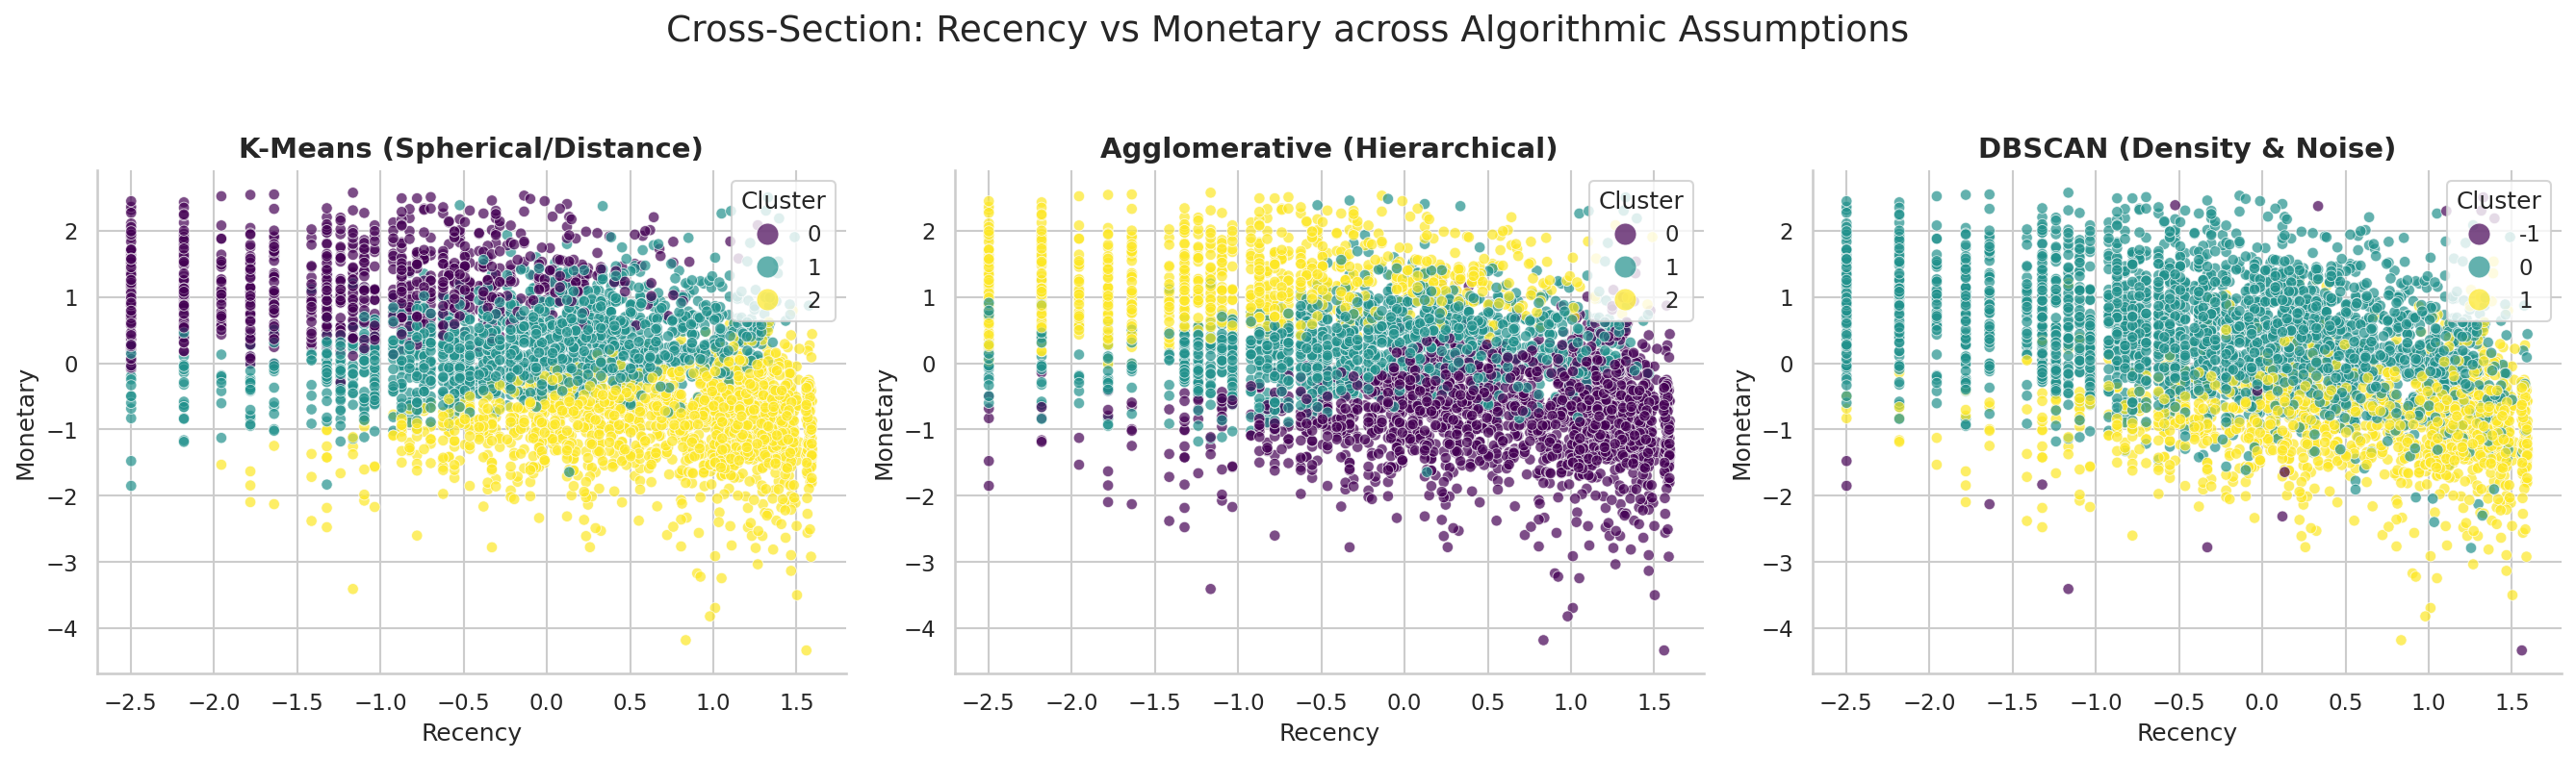

Note: In DBSCAN, cluster '-1' represents mathematically isolated anomalies (noise).


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [('KMeans_Labels', 'K-Means (Spherical/Distance)'), 
          ('Agglo_Labels', 'Agglomerative (Hierarchical)'), 
          ('DBSCAN_Labels', 'DBSCAN (Density & Noise)')]

for ax, (col, title) in zip(axes, models):
    sns.scatterplot(data=rfm_scaled, x='Recency', y='Monetary', hue=col, palette='viridis', ax=ax, alpha=0.7, s=30)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(title='Cluster', loc='upper right', bbox_to_anchor=(1, 1), markerscale=2)

plt.suptitle('Cross-Section: Recency vs Monetary across Algorithmic Assumptions', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()

print("Note: In DBSCAN, cluster '-1' represents mathematically isolated anomalies (noise).")

In [7]:
!pip install --upgrade nbformat

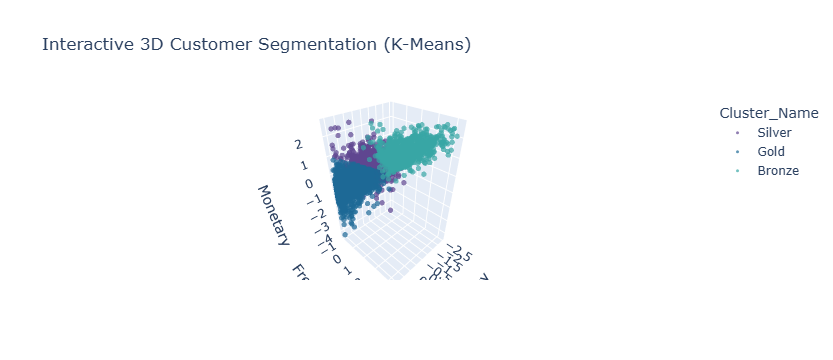

In [8]:
import plotly.express as px

# Map the winning K-Means labels to a string for categorical coloring
rfm_scaled['Cluster_Name'] = rfm_scaled['KMeans_Labels'].map({0: 'Bronze', 1: 'Silver', 2: 'Gold', 3: 'Platinum'})

fig = px.scatter_3d(
    rfm_scaled, 
    x='Recency', y='Frequency', z='Monetary',
    color='Cluster_Name',
    opacity=0.7,
    title='Interactive 3D Customer Segmentation (K-Means)',
    color_discrete_sequence=px.colors.qualitative.Prism
)
fig.update_traces(marker=dict(size=3))
fig.show()

### The "So What?" Business Action Plan
Machine learning is only as good as the business decisions it drives. Based on the geometric separation of our K-Means model, here is the targeted marketing strategy for each distinct customer cohort:

| Customer Segment | RFM Profile | Marketing Strategy & Actionable Insight |
| :--- | :--- | :--- |
| **Platinum (Champions)** | High Spend, High Freq, Very Recent | Do not offer discounts (they buy anyway). Offer early access to new products, VIP support, and loyalty rewards. |
| **Gold (Loyalists)** | Good Spend, Good Freq, Recent | Upsell higher-margin items. Encourage referrals with "Bring a Friend" campaigns. |
| **Silver (At Risk)** | Low Spend, Low Freq, High Recency | Send targeted "Win-Back" discount codes. Send personalized emails asking for feedback to prevent churn. |
| **Bronze (Lost/Noise)** | Very Low Spend, Very High Recency | Deprioritize marketing spend here. Only target during major clearance sales to clear out dead inventory. |

In [9]:
import joblib

# Save the fitted scaler and the finalized K-Means model
joblib.dump(scaler, 'rfm_scaler.pkl')
joblib.dump(kmeans_final, 'kmeans_model.pkl')

print("Deployment assets saved successfully!")

Deployment assets saved successfully!
